# 1. Imports and Dataset Loading
Load an arbitrary image to demonstrate the feature extractors on raw satellite data.


The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload
Setting up Dataset...


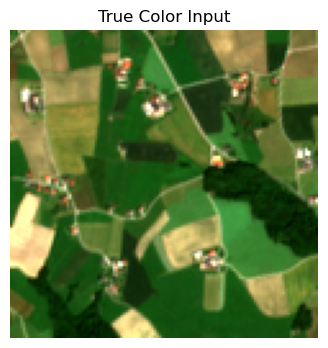

In [6]:
%load_ext autoreload
%autoreload 2
import sys
import os
sys.path.insert(0, os.path.abspath('../'))


import torch
import albumentations as A
import matplotlib.pyplot as plt
import numpy as np
from albumentations.pytorch import ToTensorV2
from datasets import ReBENDataset

from utils.features import NDILayer, HOGLayer, DifferentiableGLCM
from utils.visualization import quant_norm, generate_hog_image

print("Setting up Dataset...")

REBEN_LMDB_PATH = "/mnt/ssd/datasets/reben/BigEarthNet-S2-3%_lmdb"
REBEN_KEYS_PATH = "/mnt/ssd/datasets/reben/keys-3%.pkl"
SPLIT_FILE = "../datasets/splits/reben.parquet"

BANDS = ["B01", "B02", "B03", "B04", "B05", "B06", 
         "B07", "B08", "B8A", "B09", "B11", "B12"]
tc_idx = [BANDS.index(b) for b in ["B04", "B03", "B02"]]

ds = ReBENDataset(
    data_dir=REBEN_LMDB_PATH, 
    keys_path=REBEN_KEYS_PATH,
    align_size=(120, 120), 
    bands=BANDS,
    normalize=False, 
    transform=A.Compose([A.CenterCrop(height=120, width=120), ToTensorV2()]),
    split_file=SPLIT_FILE, 
    split="test",
    return_mask=False
)

imgs_batch = torch.stack([ds[20].float()])
img_tc = quant_norm(imgs_batch[0, tc_idx, ...]).permute(1, 2, 0).cpu().numpy()

plt.figure(figsize=(4, 4))
plt.imshow(img_tc)
plt.title("True Color Input")
plt.axis('off')
plt.show()


# 2. Normalized Difference Indices (NDI)


Testing NDILayer...


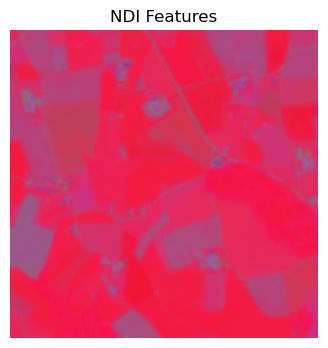

In [7]:
print("Testing NDILayer...")

ndi_layer = NDILayer(bands=BANDS)
ndi_features = ndi_layer(imgs_batch)

# Plot the first 3 NDI combinations as an RGB image for visualization
ndi_vis = ((ndi_features[0, :3] + 1.0) / 2.0).permute(1, 2, 0).cpu().numpy()

plt.figure(figsize=(4, 4))
plt.imshow(ndi_vis)
plt.title("NDI Features")
plt.axis('off')
plt.show()


# 3. Histogram of Oriented Gradients (HOG)


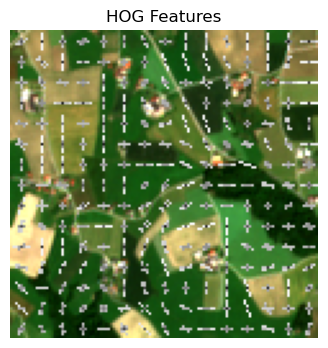

In [14]:
hog_layer = HOGLayer(nbins=9, pool=8, in_channels=len(BANDS), use_max_gradient=True, normalize=True)
hog_features = hog_layer(imgs_batch)

# Generate a visual representation of the gradients
hog_vis = generate_hog_image(hog_features[0], image=img_tc)#cell_size=8)

plt.figure(figsize=(4, 4))
plt.imshow(hog_vis, cmap='gray')
plt.title("HOG Features")
plt.axis('off')
plt.show()


# 4. Gray-Level Co-Occurrence Matrix (GLCM)


Testing DifferentiableGLCM...


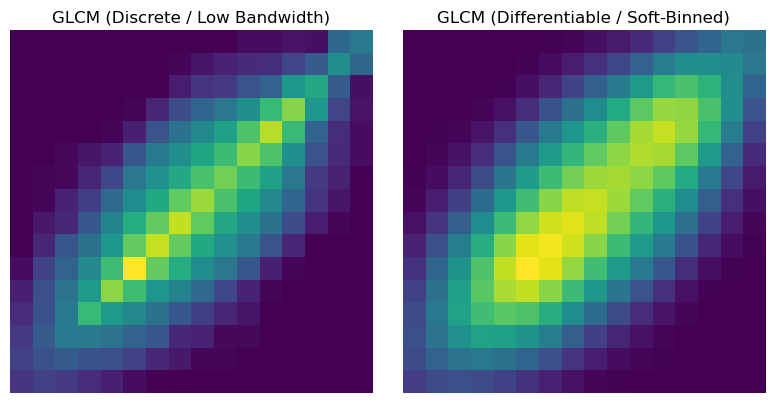

In [9]:
print("Testing DifferentiableGLCM...")

# Standardize NIR band before GLCM
nir_idx = BANDS.index("B08")
nir_band = imgs_batch[:, nir_idx, ...]  # Shape: (B, H, W)
nir_norm = (nir_band - nir_band.mean(dim=(1, 2), keepdim=True)) / (nir_band.std(dim=(1, 2), keepdim=True) + 1e-6)

# 1. 'Discrete' GLCM (emulated via very low bandwidth)
glcm_discrete = DifferentiableGLCM(bins=16, min_val=-3.0, max_val=3.0, bandwidth=1e-4)
glcm_feat_disc = glcm_discrete(nir_norm)
vis_disc = np.log1p(glcm_feat_disc[0].cpu().numpy() * 1e4)

# 2. Differentiable GLCM (soft-binned via KDE)
glcm_diff = DifferentiableGLCM(bins=16, min_val=-3.0, max_val=3.0, bandwidth=0.1875)
glcm_feat_diff = glcm_diff(nir_norm)
vis_diff = np.log1p(glcm_feat_diff[0].cpu().numpy() * 1e4)

fig, axes = plt.subplots(1, 2, figsize=(8, 4))
axes[0].imshow(vis_disc, cmap='viridis', origin='lower')
axes[0].set_title("GLCM (Discrete / Low Bandwidth)")
axes[0].axis('off')

axes[1].imshow(vis_diff, cmap='viridis', origin='lower')
axes[1].set_title("GLCM (Differentiable / Soft-Binned)")
axes[1].axis('off')

plt.tight_layout()
plt.show()
